# 04 · Few labels: does self-supervised pretraining help?

> **New to this?** Every term is explained in plain words in the [glossary](glossary.ipynb).

**The question.** Labels are scarce in this challenge; unlabelled scan is not. If we first teach the encoder papyrus
texture from **unlabelled** layers, does it then learn ink from fewer labels than an encoder trained from scratch?

**Why it is worth asking.** A closed scroll holds terabytes of scan and only a few labelled strokes. Every scroll is a
new domain (open problem 7). If an encoder can learn papyrus from the scroll itself, without labels, it might adapt to a
new scroll where no labels exist. The challenge is betting on this too: open problem 9 is self-supervised 3D
representations, and its "dinovol" model is a DINO-style 3D encoder for the volumes.

**The family of methods.**

| method | pretext task | what it must learn | here |
|---|---|---|---|
| masked image modelling (MAE, SimMIM) | hide blocks, reconstruct them | local texture, how layers continue in depth | **this notebook** |
| contrastive (SimCLR) | two augmented views of one patch must match, other patches must not | what survives the augmentations | try next |
| self-distillation (DINO, dinovol) | a student matches a slowly updated teacher across views | invariant features without negatives | the challenge's 3D encoder |

**The pretext task: masked image modelling** (SimMIM-style). Hide 60% of the 8 × 8 pixel blocks of a 16-layer patch
(all layers at once) and train the network to reconstruct the hidden voxels. To do that it must model fibre texture and
the depth profile of the sheet, and it never sees a label.

**The experiment.**

| | |
|---|---|
| data | segment w025, 16 surface layers, level 1 (from notebook 03) |
| label | the official ink prediction (pseudo-label), as in notebook 03 |
| labelled pool | 128 × 128 tiles from the left 60% of the sheet; we reveal 2%, 10%, 50% or 100% of them |
| pretraining data | every tile of the left 60%, **labels unused** |
| validation | the same 512 patches from the right 40%, never seen by either stage |
| arms | scratch vs pretrained encoder, the same head, the same steps, the same seed |

**What would make SSL win:** its held-out correlation is above scratch at small label fractions, and the gap shrinks
as the fraction grows. If the curves overlap, the pretext did not teach anything ink-relevant at this scale.

In [ ]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [1]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
import inklab as K
Xn, Y, valid = K.load()
cut = int(Xn.shape[2] * 0.6)
pool = K.tiles(valid, cut); xv, yv = K.val_set(Xn, Y, valid, cut)
print('device', K.DEV, '| layers', Xn.shape[0], '| labelled pool', len(pool), 'tiles of 128 x 128 | val patches', len(xv))

device mps | layers 16 | labelled pool 346 tiles of 128 x 128 | val patches 512


## 1. Pretext: reconstruct masked blocks

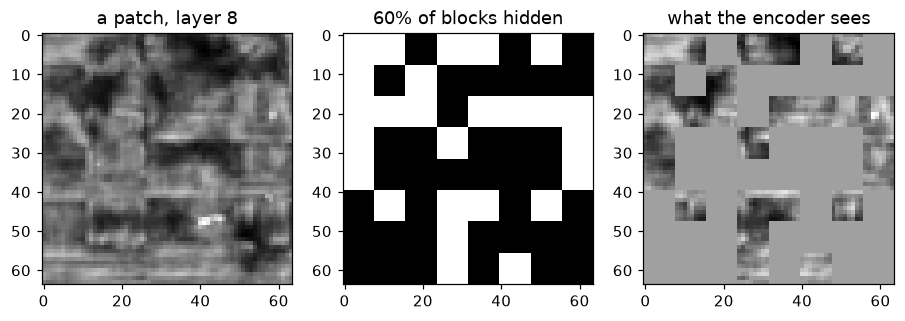

In [3]:
def mask_blocks(x, ratio, rng, b=8):
    B, L, H, W = x.shape
    m = torch.tensor(rng.random((B, 1, H // b, W // b)) < ratio, dtype=torch.float32)
    m = m.repeat_interleave(b, 2).repeat_interleave(b, 3)        # (B, 1, H, W): 1 = hidden
    return x * (1 - m), m
rng = np.random.default_rng(0); xb, _ = K.sample(Xn, Y, pool, 4, rng); xm, m = mask_blocks(xb, 0.6, rng)
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(xb[0, 8]); ax[0].set_title('a patch, layer 8'); ax[1].imshow(m[0, 0], cmap='gray_r'); ax[1].set_title('60% of blocks hidden')
ax[2].imshow(xm[0, 8]); ax[2].set_title('what the encoder sees'); plt.show()

In [4]:
torch.manual_seed(0); rng = np.random.default_rng(1)
enc_ssl = K.Encoder().to(K.DEV); rec = K.head(32, Xn.shape[0]).to(K.DEV)
opt = torch.optim.AdamW(list(enc_ssl.parameters()) + list(rec.parameters()), 2e-3, weight_decay=1e-4)
t = time.time(); curve = []
for step in range(1, 1501):
    xb, _ = K.sample(Xn, Y, pool, 16, rng); xm, m = mask_blocks(xb, 0.6, rng)
    out = rec(enc_ssl(xm.to(K.DEV)))
    loss = (((out - xb.to(K.DEV)) ** 2) * m.to(K.DEV)).sum() / (m.sum() * Xn.shape[0]).to(K.DEV)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 250 == 0: curve.append((step, loss.item())); print(f'pretrain step {step} masked MSE {loss.item():.4f} ({time.time() - t:.0f}s)')
SSL_STATE = {k: v.detach().clone() for k, v in enc_ssl.state_dict().items()}

pretrain step 250 masked MSE 0.3266 (91s)


pretrain step 500 masked MSE 0.3055 (184s)


pretrain step 750 masked MSE 0.2480 (282s)


pretrain step 1000 masked MSE 0.2252 (377s)


pretrain step 1250 masked MSE 0.2369 (485s)


pretrain step 1500 masked MSE 0.2270 (594s)


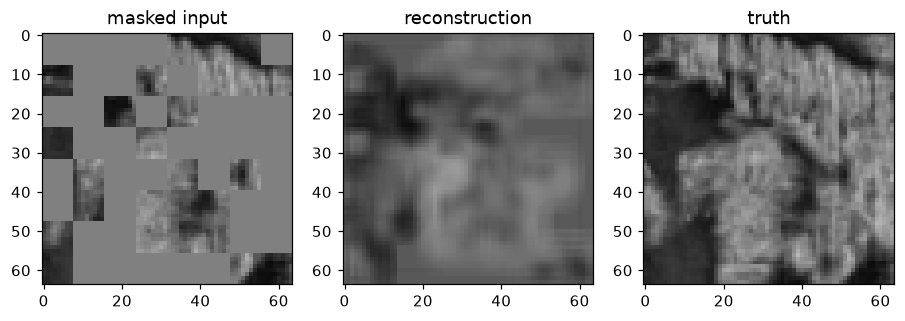

In [5]:
with torch.no_grad():
    xb, _ = K.sample(Xn, Y, pool, 1, np.random.default_rng(5)); xm, m = mask_blocks(xb, 0.6, np.random.default_rng(6))
    out = rec(enc_ssl(xm.to(K.DEV))).cpu()
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a, im, t in zip(ax, [xm[0, 8], out[0, 8], xb[0, 8]], ['masked input', 'reconstruction', 'truth']): a.imshow(im, vmin=-2, vmax=2); a.set_title(t)
plt.show()

If the reconstruction fills the hidden blocks with plausible fibre texture, the encoder has learned something about
papyrus without a single label. Whether that something is *ink-relevant* is what the next section measures.

## 2. Fine-tune with few labels: scratch vs pretrained

In [6]:
def encoder(pretrained):
    e = K.Encoder()
    if pretrained: e.load_state_dict(SSL_STATE)
    return e
fracs, STEPS, rows = [0.02, 0.10, 0.50, 1.00], 600, []
for f in fracs:
    sub = [pool[i] for i in np.random.default_rng(42).permutation(len(pool))[:max(1, int(round(f * len(pool))))]]
    for arm in ('scratch', 'pretrained'):
        t = time.time(); c, _ = K.finetune(encoder(arm == 'pretrained'), Xn, Y, sub, xv, yv, STEPS, seed=0)
        rows.append((f, len(sub), arm, c)); print(f'labels {f:4.0%} ({len(sub):3d} tiles)  {arm:10s}  held-out corr {c:.3f}  ({time.time() - t:.0f}s)')

labels   2% (  7 tiles)  scratch     held-out corr 0.190  (244s)


labels   2% (  7 tiles)  pretrained  held-out corr 0.182  (243s)


labels  10% ( 35 tiles)  scratch     held-out corr 0.243  (231s)


labels  10% ( 35 tiles)  pretrained  held-out corr 0.264  (231s)


labels  50% (173 tiles)  scratch     held-out corr 0.221  (242s)


labels  50% (173 tiles)  pretrained  held-out corr 0.152  (241s)


labels 100% (346 tiles)  scratch     held-out corr 0.196  (216s)


labels 100% (346 tiles)  pretrained  held-out corr 0.206  (218s)


arm             pretrained  scratch  pretrained - scratch
fraction tiles                                           
0.02     7           0.182    0.190                -0.007
0.10     35          0.264    0.243                 0.022
0.50     173         0.152    0.221                -0.068
1.00     346         0.206    0.196                 0.009


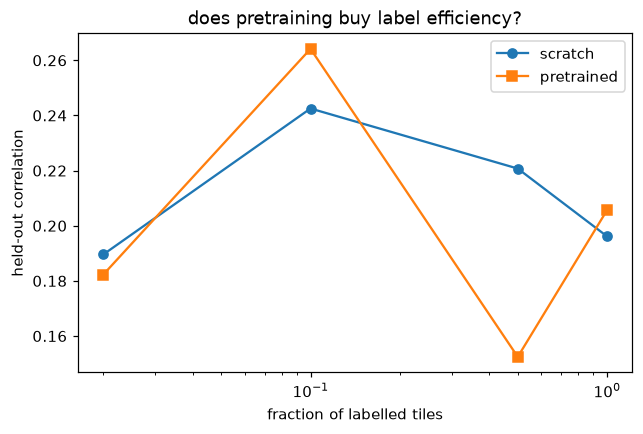

In [7]:
import pandas as pd
R = pd.DataFrame(rows, columns=['fraction', 'tiles', 'arm', 'corr']).pivot(index=['fraction', 'tiles'], columns='arm', values='corr')
R['pretrained - scratch'] = R['pretrained'] - R['scratch']; print(R.round(3).to_string())
plt.figure(figsize=(6.5, 4))
for arm, mk in (('scratch', 'o-'), ('pretrained', 's-')): plt.semilogx([f for f, _ in R.index], R[arm], mk, label=arm)
plt.xlabel('fraction of labelled tiles'); plt.ylabel('held-out correlation'); plt.legend(); plt.title('does pretraining buy label efficiency?'); plt.show()

## Reading the result

**Measured:** pretraining gives no consistent gain. The difference "pretrained − scratch" is −0.007, +0.022, −0.068 and
+0.009 at 2%, 10%, 50% and 100% of the labels: no direction, and no shrinking gap as labels grow. That is the pattern
the experiment called a null in its opening table.

- **One seed per cell.** Two runs differing only in their seed can move by a few hundredths at 600 steps, so a gap
  smaller than that is not evidence. Rerun with seeds 1 and 2 before believing a small difference.
- **Why scratch at 100% scores 0.196 here and 0.315 in notebook 03.** This notebook fine-tunes for 600 steps; notebook
  03 trains for 1,500 and its curve was still rising. Both arms here are undertrained by the same amount, which is fair
  between them but not comparable with 03.
- The label is a pseudo-label (notebook 03). "Better" means "closer to the 2.4 µm model", not "closer to the true ink".
- Pretraining used only the left 60% too. Pretraining on the validation strip's unlabelled pixels is allowed in
  practice (you always have the unlabelled scroll you want to read), and is a fair follow-up: it is test-time
  self-supervision, aimed at the cross-scroll problem.

**Why masking might not help here, as hypotheses** (HYPOTHESIS, unverified):

1. Reconstructing 8 × 8 blocks of fibre texture can be done from the visible neighbours without modelling ink at all.
   Ink is a small fraction of the pixels; a reconstruction loss barely notices it.
2. 1,500 pretraining steps on one segment is tiny next to MAE-scale pretraining.
3. The pseudo-label measures closeness to another model, so a better ink feature can still score worse.

## Try next

1. Mask ratio 0.4 vs 0.8; block size 4 vs 16.
2. Mask whole *layers* instead of blocks: the model must infer depth structure.
3. SimCLR instead of masking: two augmented views of one patch as positives.
4. Pretrain on a different segment, fine-tune on this one: does the texture knowledge transfer?
5. Three seeds per cell, so a 0.02 difference can be told from noise.
6. Use the challenge's pretrained `dinovol` encoder as the frozen backbone instead of our own pretraining.

## Check yourself

1. Why is the validation strip excluded from *pretraining* in this experiment?
2. Why does the gap between the arms have to shrink as labels grow, if SSL is working?
3. What would it mean if the pretrained arm were **worse** at 100% labels?